In [16]:
import numpy as np
import rasterio as rio
from rasterio.windows import Window
from rasterio import Affine
from osgeo import gdal
from pathlib import Path
import glob
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds, Window
from tqdm import tqdm
from matplotlib import pyplot as plt

In [ ]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"

In [13]:
country_raster_1km_  = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif')

In [6]:
input_dir = DATA / 'GSDS30'
output_dir = RESULTS / 'GSDS30-1km'
output_dir.mkdir(exist_ok=True)

In [10]:
gg = rio.open(input_dir / '0E10N.tif')

In [11]:
gg.transform

Affine(30.0, 0.0, -1470450.0,
       0.0, -30.0, 1722630.0)

In [ ]:
gg.crs.to_string()

'EPSG:3857'

In [12]:
gg.shape

(50000, 50000)

In [14]:
country_raster_1km_.transform

Affine(1000.0, 0.0, -16922000.0,
       0.0, -1000.0, 8461000.0)

In [19]:
country_raster_1km_.crs.to_string()

'ESRI:54012'

In [21]:
# --- destination template (defines global 1 km Eckert IV grid) ---
with rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif') as ref:
    dst_crs, dst_transform = ref.crs, ref.transform
    dst_h, dst_w = ref.height, ref.width

In [22]:
profile = dict(driver='GTiff', dtype='float32', count=1,
               width=dst_w, height=dst_h, crs=dst_crs, transform=dst_transform,
               compress='lzw', tiled=True, bigtiff='IF_SAFER', nodata=None)

In [ ]:
classes = [1, 2, 3]
out_paths = {c: output_dir / f'class{c}-frac-1km.tif' for c in classes}

In [24]:
# pre-create empty global outputs (zeros)
for c in classes:
    with rio.open(out_paths[c], 'w', **profile):
        pass

In [26]:
# --- iterate over native 30 m tiles ---
dsts = {c: rio.open(out_paths[c], 'r+') for c in classes}
try:
    tile_list = sorted(input_dir.glob('*.tif'))
    for tile_path in tqdm(tile_list, desc='Tiles'):
    # for tile_path in sorted(input_dir.glob('*.tif')):
        with rio.open(tile_path) as src:
            # tile bounds → destination CRS (densify because projection edges curve)
            l, b, r, t = transform_bounds(src.crs, dst_crs, *src.bounds, densify_pts=21)
            win = from_bounds(l, b, r, t, dst_transform).round_offsets().round_lengths()
            win = win.intersection(Window(0, 0, dst_w, dst_h))
            if win.width <= 0 or win.height <= 0:
                continue
            win_transform = rio.windows.transform(win, dst_transform)
            wh, ww = int(win.height), int(win.width)

            src_arr = src.read(1)  # uint8, ~2.5 GB

            # for c in classes:
            for c in tqdm(classes, desc=tile_path.stem, leave=False):  # ← inner (optional)
                mask = (src_arr == c).astype(np.uint8)   # 0/1
                out = np.zeros((wh, ww), dtype=np.float32)
                reproject(
                    source=mask, destination=out,
                    src_transform=src.transform, src_crs=src.crs,
                    dst_transform=win_transform, dst_crs=dst_crs,
                    resampling=Resampling.average,       # → fraction in [0,1]
                )
                existing = dsts[c].read(1, window=win)
                dsts[c].write(np.maximum(existing, out), 1, window=win)  # tile-edge safe
            del src_arr

        print(f'done: {tile_path.name}')

finally:
    for d in dsts.values():
        d.close()

Tiles:   0%|          | 1/316 [00:54<4:45:02, 54.30s/it]

done: 0E10N.tif


Tiles:   1%|          | 2/316 [01:45<4:33:31, 52.27s/it]

done: 0E20N.tif


Tiles:   1%|          | 3/316 [02:38<4:35:57, 52.90s/it]

...

done: 90W80N-2.tif


Tiles: 100%|█████████▉| 315/316 [5:42:33<01:56, 116.43s/it]

done: 90W80N-3.tif


Tiles: 100%|██████████| 316/316 [5:45:30<00:00, 65.60s/it] 

done: 90W80N.tif


In [20]:
out_paths = [
    RESULTS / 'GSDS30-1km' / 'class1-frac-1km.tif',
    RESULTS / 'GSDS30-1km' / 'class2-frac-1km.tif',
    RESULTS / 'GSDS30-1km' / 'class3-frac-1km.tif'
]

In [21]:
c1 = rio.open(out_paths[0]).read(1)
c2 = rio.open(out_paths[1]).read(1)
c3 = rio.open(out_paths[2]).read(1)

In [22]:
total = c1 + c2 + c3

In [23]:
print('non-zero cells:', np.sum(total > 0))
print('total stats: min/mean/max =',
      total[total > 0].min(), total[total > 0].mean(), total[total > 0].max())
print('cells with total > 1.001:', np.sum(total > 1.001))   # should be 0
print('cells with 0 < total < 0.999:', np.sum((total > 0) & (total < 0.999)))

non-zero cells: 135256274
total stats: min/mean/max = 1.38457406e-08 0.99455976 1.8597102
cells with total > 1.001: 7481
cells with 0 < total < 0.999: 1438939


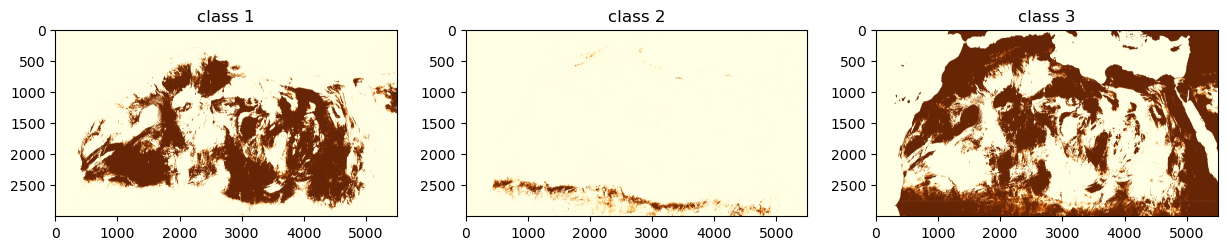

In [45]:
# Sahara window in Eckert IV — pick a chunk roughly over Algeria/Libya
win = rio.windows.Window(15000, 3700, 5500, 3000)  # adjust to your grid

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate([1, 2, 3]):
    arr = rio.open(out_paths[i]).read(1, window=win)
    ax[i].imshow(arr, vmin=0, vmax=1, cmap='YlOrBr')
    ax[i].set_title(f'class {c}')

plt.show()